# RAG 지도

**이 노트북에서 할 일**

1. 도서관 안내 PDF(E01) 5쪽을 쪽마다 읽어 문서 청크로 나누고, 임베딩해 벡터스토어에 넣습니다.
2. 질문과 가까운 문서 청크를 검색하고, 가져오는 개수 k를 2와 1로 바꿔 출처를 비교합니다.
3. 검색 없이 질문만 보낸 Before와, 검색한 근거를 넣은 After의 답과 출처 표시를 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 `labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.

인터넷 서비스에 요청을 모두 7번 보냅니다. 임베딩 모델 `text-embedding-3-small`에 4번, `gpt-5.4-mini`에 3번입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
mini 요금은 Ch 6 06절에서 확인한 값입니다.

**강의와 실습 범위** — 강의 시간에는 2~6절(PDF 읽기, 문서 청크, 임베딩, 검색, k 비교)을 설명합니다.
7~8절(메시지 목록, 답 받기)과 Before·After는 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. pypdf 6.17.0, langchain 1.4.0, langchain-core 1.6.2입니다.
함께 쓰는 판은 langchain-openai 1.6.0, langchain-text-splitters 1.1.2입니다.
나머지는 openai 3.8.0과 python-dotenv 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch09-rag-first-run`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

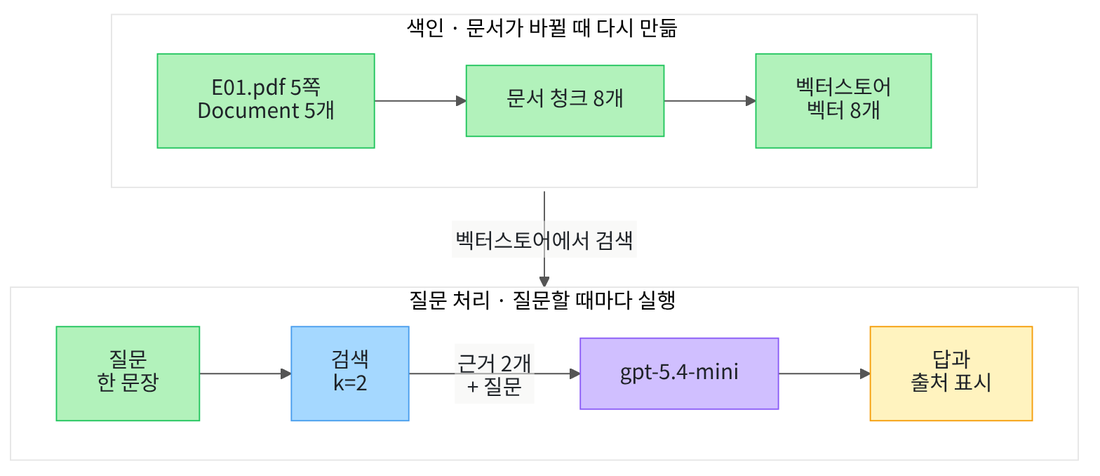

위 칸은 문서가 바뀔 때 다시 만드는 색인, 아래 칸은 질문할 때마다 실행하는 질문 처리입니다.
두 칸은 벡터스토어에서 만납니다. 초록 상자는 넣은 자료, 파란 상자는 코드 단계, 보라 상자는 모델입니다.
노란 상자는 출력으로 확인할 값입니다. 노트북 2~4절이 위 칸, 5~8절이 아래 칸을 차례로 실행합니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
Ch 8과 달리 PDF를 읽는 pypdf, 글을 나누는 langchain-text-splitters를 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.17.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langchain-text-splitters==1.1.2" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.17.0
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langchain-text-splitters: 1.1.2
openai: 3.8.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `pypdf: 6.17.0`, `langchain: 1.4.0`, `openai: 3.8.0` 등 일곱 줄입니다.
준비물에 적은 기준 버전과 같습니다.

PDF 읽기, 문서 객체, 글 나누기, 임베딩, 벡터스토어, 모델 준비에 쓸 이름을 불러옵니다.
이름마다 처음 쓰는 절에서 무엇을 넣고 무엇을 반환하는지 설명합니다.

In [2]:
# PDF 읽기·문서 청크 나누기·임베딩·벡터스토어·모델 준비에 쓸 이름을 불러옵니다
import os

from pypdf import PdfReader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain.chat_models import init_chat_model

Ch 8과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


Ch 8과 같은 설정으로 답을 쓸 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다.
실행마다 답 문장이 달라질 수 있습니다. Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정과 같은 것이 아닙니다.

## 2. PDF 파일을 찾아 쪽마다 읽기

노트북을 연 폴더에 따라 PDF까지 가는 경로가 다릅니다. Ch 8 06절처럼 후보 경로를 차례로 확인하고, 있는 경로에서 멈춥니다.
함수 `os.path.exists()`는 경로를 받아 파일이 있으면 `True`를 반환합니다.

후보는 세 개입니다. 프로젝트 맨 위, 실습 폴더 맨 위, `notebooks` 폴더에서 연 경우입니다.
실행 전에 예상합니다. `notebooks` 폴더에서 열었다면 셋째 후보, 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [5]:
# 작업 폴더에서 본 E01.pdf 경로를 후보 세 개 가운데에서 고릅니다
candidates = [
    "labs/data/rag-corpus/pdf/easy/E01.pdf",
    "../../data/rag-corpus/pdf/easy/E01.pdf",
    "../../../data/rag-corpus/pdf/easy/E01.pdf",
]
pdf_path = None
for candidate in candidates:
    if os.path.exists(candidate):
        pdf_path = candidate
        break
print("PDF를 찾았는가:", pdf_path is not None)
print("고른 경로:", pdf_path)
assert pdf_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

PDF를 찾았는가: True
고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf


**결과 읽기** — 출력 줄은 `PDF를 찾았는가: True`와 `고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보, 실습 폴더 맨 위에서 열면 둘째 후보가 나옵니다.

라이브러리 pypdf의 `PdfReader`에 경로를 넣으면 PDF 객체를 반환합니다. 속성 `pages`는 쪽 목록입니다.
쪽 하나의 메서드 `extract_text()`는 그 쪽의 글을 문자열로 반환합니다.
Ch 8에서는 E01 2쪽 글을 사람이 옮겨 적었습니다. 이번에는 코드가 읽은 글이 Ch 8 글과 같은지 확인합니다.

In [6]:
# PDF의 쪽 수를 보고, 2쪽 글을 꺼내 「휴관」이 든 줄만 출력합니다
reader = PdfReader(pdf_path)
print("쪽 수:", len(reader.pages))
page_two_text = reader.pages[1].extract_text()
print("2쪽 글자 수:", len(page_two_text))
print("2쪽에서 「휴관」이 든 줄:")
for line in page_two_text.split("\n"):
    if "휴관" in line:
        print(line)
print("Ch 8 글 「정기 휴관일입니다」가 있는가:", "정기 휴관일입니다" in page_two_text)

쪽 수: 5
2쪽 글자 수: 905
2쪽에서 「휴관」이 든 줄:
매주 월요일은 정기 휴관일 입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.
Ch 8 글 「정기 휴관일입니다」가 있는가: False


**결과 읽기** — 출력 줄은 `쪽 수: 5`와 `2쪽 글자 수: 905`입니다.
라벨 줄 아래 두 줄이 「휴관」이 든 줄입니다. 첫 줄은 `매주 월요일은 정기 휴관일 입니다.`로 시작하고, 문장이 `그 다음 날인`에서 줄이 바뀝니다.
마지막 줄은 `Ch 8 글 「정기 휴관일입니다」가 있는가: False`입니다.

PDF에서 읽은 글은 「휴관일 입니다」처럼 띄어쓰기 한 곳이 Ch 8 글과 다르고, PDF 줄 끝에서 문장이 끊깁니다.
Ch 8은 이 띄어쓰기를 사람이 고쳐 옮겼습니다. 이 노트북은 PDF에서 읽은 글을 고치지 않고 그대로 씁니다.

다섯 쪽을 모두 문서 객체로 바꿉니다. 문서 객체 `Document`는 본문 `page_content`와 설명 값 `metadata`를 한 묶음으로 담는 LangChain 객체입니다.
메타데이터는 Ch 8 02절에서 배운 대로 내용 옆에 적어 두고 찾거나 고를 때 쓰는 설명 값입니다. 여기에는 문서 이름 `doc_id`와 쪽 번호 `page`를 적습니다.

In [7]:
# 다섯 쪽을 차례로 읽어, 쪽마다 본문과 메타데이터를 담은 Document 목록을 만듭니다
pages = []
page_number = 1
for page in reader.pages:
    page_document = Document(
        page_content=page.extract_text(),
        metadata={"doc_id": "E01", "page": page_number, "source": "E01.pdf"},
    )
    pages.append(page_document)
    page_number = page_number + 1
print("Document 수:", len(pages))
print("2쪽 메타데이터:", pages[1].metadata)

Document 수: 5
2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}


**결과 읽기** — 출력 줄은 `Document 수: 5`와 `2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`입니다.

목록 번호는 0부터 세므로 `pages[1]`이 2쪽입니다. 쪽 번호는 사람이 읽는 번호라 1부터 적었습니다.

## 3. 쪽을 문서 청크로 나누기

한 쪽은 900자 안팎이라 검색해서 넣기에는 깁니다. 그래서 쪽을 더 작은 글 묶음으로 나눕니다.
이렇게 검색 단위로 자른 문서의 한 부분을 문서 청크(chunk)라고 부릅니다. 긴 공지문을 문단 카드 몇 장에 나눠 옮기는 것과 비슷합니다.

Ch 6 04절에서 스트리밍으로 도착한 답의 일부(스트림 청크)와는 다른 것입니다. Ch 5에서 「조각」이라고 부른 토큰과도 다릅니다.

도구 `RecursiveCharacterTextSplitter`는 글자 수 기준으로 글을 나눕니다. 인자 `chunk_size=500`은 한 문서 청크의 최대 글자 수입니다.
인자 `chunk_overlap=50`은 이웃한 두 문서 청크가 함께 갖는 글자 수입니다. 메서드 `split_documents()`는 Document 목록을 받아 더 작은 Document 목록을 반환합니다.

실행 전에 예상합니다. 짧은 1쪽은 하나, 긴 쪽은 둘로 나뉠 것입니다.

In [8]:
# 다섯 쪽을 500자 안팎의 문서 청크로 나누고, 문서 청크마다 쪽 번호와 글자 수를 출력합니다
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(pages)
print("문서 청크 수:", len(chunks))
print("문서 청크(쪽 | 글자 수):")
for chunk in chunks:
    print(chunk.metadata["page"], "|", len(chunk.page_content))

문서 청크 수: 8
문서 청크(쪽 | 글자 수):
1 | 45
2 | 498
2 | 452
3 | 498
3 | 462
4 | 492
4 | 412
5 | 270


**결과 읽기** — 첫 줄은 `문서 청크 수: 8`입니다. 라벨 줄 아래 여덟 줄은 쪽 번호와 글자 수입니다.
1쪽은 `1 | 45` 한 줄, 2쪽은 `2 | 498`과 `2 | 452` 두 줄입니다. 5쪽은 `5 | 270` 한 줄입니다.

1쪽은 표지라 45자뿐이어서 나뉘지 않았습니다. 문서 청크마다 원래 쪽의 메타데이터가 그대로 복사되어, 나뉜 뒤에도 쪽 번호를 읽을 수 있습니다.
나누는 규칙과 겹침은 02절에서 자세히 봅니다.

## 4. 문서 청크를 임베딩해 벡터스토어에 넣기

임베딩(embedding)은 글을 뜻이 비슷하면 가까운 숫자 목록(벡터)으로 바꾸는 일입니다. Ch 5 02절에서는 내 컴퓨터의 모델로 문장 하나를 숫자 384개로 바꿨습니다.
이번에는 OpenAI 임베딩 모델 `text-embedding-3-small`을 인터넷 서비스로 부릅니다.

클래스 `OpenAIEmbeddings`에 모델 이름을 넣어 임베딩 객체를 만듭니다. 메서드 `embed_query()`는 글 하나를 받아 숫자 목록을 반환합니다.
질문은 Ch 8 03절의 휴관일 질문과 같은 글입니다. 이 셀은 임베딩 요청을 1번 보냅니다.

실행 전에 예상합니다. 질문의 글자 수와 관계없이 숫자 개수는 정해져 있을 것입니다.

In [9]:
# 임베딩 객체를 만들고, 질문 한 문장을 숫자 목록으로 바꿔 길이를 봅니다(임베딩 요청 1번)
embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")
question_text = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
question_vector = embedding_model.embed_query(question_text)
print("질문 글자 수:", len(question_text))
print("질문 벡터의 숫자 개수:", len(question_vector))
first_numbers = question_vector[:3]
print("앞 숫자 세 개:", first_numbers)

질문 글자 수: 45
질문 벡터의 숫자 개수: 1536
앞 숫자 세 개: [-0.007572174072265625, 0.06585693359375, 0.053009033203125]


**결과 읽기** — 출력 줄은 `질문 글자 수: 45`와 `질문 벡터의 숫자 개수: 1536`입니다. 마지막 줄은 앞 숫자 세 개입니다.
OpenAI 임베딩 안내도 이 모델의 기본 벡터 길이를 1536으로 적습니다. 숫자 하나하나의 뜻은 사람이 읽지 않습니다.
앞 숫자는 실행마다 조금 달라질 수 있어 비교에 쓰지 않습니다.

벡터스토어(vector store)는 문서 청크와 그 벡터를 함께 담아 두고, 질문 벡터와 가까운 것을 찾아 주는 저장소입니다.
메서드 `InMemoryVectorStore.from_documents()`는 문서 청크 목록과 임베딩 객체를 받아, 모든 문서 청크를 임베딩해 담은 저장소를 반환합니다.
저장소는 파일에 쓰지 않고 이 노트북의 메모리에만 있습니다. 여덟 문서 청크를 한 요청으로 보냅니다.

In [10]:
# 문서 청크 8개를 임베딩해 메모리 안의 벡터스토어에 넣습니다(임베딩 요청 1번)
store = InMemoryVectorStore.from_documents(chunks, embedding_model)
print("벡터스토어에 넣은 문서 청크 수:", len(store.store))

벡터스토어에 넣은 문서 청크 수: 8


**결과 읽기** — 출력 줄은 `벡터스토어에 넣은 문서 청크 수: 8`입니다. 3절의 문서 청크 수와 같습니다.
속성 `store`는 넣은 문서 청크와 벡터를 담은 딕셔너리이고, 여기서는 개수만 셌습니다.

여기까지가 색인(indexing)입니다. 색인은 검색할 수 있게 문서를 미리 나누고 임베딩해 담아 두는 준비 작업입니다.
PDF 글, 나누는 설정, 임베딩 모델 가운데 하나가 바뀌면 색인을 다시 만듭니다. 질문만 바뀌면 다시 만들지 않습니다.

## 5. 질문과 가까운 문서 청크 검색하기

메서드 `similarity_search()`는 질문 글과 개수 `k`를 받습니다. 안에서 질문을 임베딩하고, 코사인 유사도가 큰 문서 청크부터 k개를 반환합니다.
코사인 유사도는 Ch 5 02절에서 직접 계산해 본 두 벡터의 가까운 정도입니다. 이렇게 가까운 순서로 k개를 가져오는 검색을 top-k 검색이라고 부릅니다.

검색한 문서 청크마다 출처 표시를 만듭니다. 모양은 Ch 8과 같은 `[E01 p.2]`입니다. 변수만 넣은 f-string(Ch 2 01절)으로 메타데이터 두 값을 이어 씁니다.
실행 전에 예상합니다. 휴관 문장이 든 2쪽 문서 청크가 목록에 들어올 것입니다.

In [11]:
# 질문과 가까운 문서 청크 2개를 검색해, 출처 표시와 앞부분 글을 출력합니다(임베딩 요청 1번)
hits = store.similarity_search(question_text, k=2)
hit_marks = []
print("k=2 검색 결과(출처 | 글자 수 | 앞 20자):")
for hit in hits:
    doc_id = hit.metadata["doc_id"]
    page = hit.metadata["page"]
    source_mark = f"[{doc_id} p.{page}]"
    hit_marks.append(source_mark)
    front_text = hit.page_content[:20].replace("\n", " ")
    print(source_mark, "|", len(hit.page_content), "|", front_text)

k=2 검색 결과(출처 | 글자 수 | 앞 20자):
[E01 p.1] | 45 | 미르시립도서관 이용 안내 미르시립도서
[E01 p.2] | 498 | 1. 도서관 소개 미르시립도서관은 1


**결과 읽기** — 라벨 줄 아래 두 줄이 가까운 순서입니다. 첫 줄은 `[E01 p.1] | 45 | 미르시립도서관 이용 안내 미르시립도서`입니다.
둘째 줄은 `[E01 p.2] | 498 | 1. 도서관 소개 미르시립도서관은 1`입니다.

1위는 표지 문서 청크였습니다. 표지에는 질문에 나온 「미르시립도서관」이 있고 다른 글이 거의 없습니다.
2위 문서 청크 498자 안에 3절에서 본 휴관 문장이 들어 있습니다. 앞 20자만 출력해서 여기서는 보이지 않고, 7절 user 글에서 보입니다.
가까운 순서는 뜻이 비슷한 정도로 매긴 것이고, 답이 들어 있는지를 판정한 것이 아닙니다.

## 6. 값 바꿔 보기 — k를 1로 줄이기

바꾸는 값은 가져오는 개수 k 하나입니다. 질문, 임베딩 모델, 벡터스토어는 그대로 둡니다.
실행 전에 예상합니다. 가까운 순서가 같다면 5절의 1위만 남을 것입니다.

In [12]:
# 같은 질문으로 k만 1로 바꿔 검색하고, 출처 표시를 모읍니다(임베딩 요청 1번)
hits_k1 = store.similarity_search(question_text, k=1)
marks_k1 = []
for hit in hits_k1:
    doc_id = hit.metadata["doc_id"]
    page = hit.metadata["page"]
    marks_k1.append(f"[{doc_id} p.{page}]")
print("k=2 출처:", hit_marks)
print("k=1 출처:", marks_k1)
assert len(hits_k1) == 1

k=2 출처: ['[E01 p.1]', '[E01 p.2]']
k=1 출처: ['[E01 p.1]']


**결과 읽기** — 출력 줄은 `k=2 출처: ['[E01 p.1]', '[E01 p.2]']`와 `k=1 출처: ['[E01 p.1]']`입니다. `assert`도 통과했습니다.

개수 k를 1로 줄이자 휴관 문장이 든 2쪽 문서 청크가 빠지고 표지만 남았습니다. 이 목록을 근거로 넣으면 답에 쓸 문장이 없습니다.
그래서 답을 받기 전에 검색 결과의 출처와 본문을 먼저 확인합니다. 이 노트북은 k=2 결과로 이어 갑니다.

## 7. 검색 결과로 메시지 목록 만들기

메시지 목록은 Ch 7·8과 같은 모양입니다. system에는 페르소나, developer에는 과업 명세, user에는 근거와 질문을 넣습니다.
Ch 8 과업 명세는 출처 예시 `[E01 p.2]`를 적었습니다. 이번에는 검색이 출처를 고르므로, 근거 앞에 붙은 출처 표시를 그대로 적게 합니다.

In [13]:
# system에 넣을 페르소나와 developer에 넣을 과업 명세를 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 과업 명세 줄에는 실제 쪽 번호가 없습니다.

5절 검색 결과로 user 글을 만듭니다. 문서 청크마다 출처 표시, 빈칸 한 칸, 본문, 빈 줄을 이어 붙입니다.
긴 글은 Ch 7 03절처럼 같은 이름에 `+`로 이어 다시 담습니다. 마지막에 `질문: `과 질문을 붙입니다.

In [14]:
# 검색한 문서 청크 2개에 출처 표시를 붙여 근거 글을 만들고, 질문을 이어 user 글과 메시지 목록을 만듭니다
evidence_text = ""
for hit in hits:
    doc_id = hit.metadata["doc_id"]
    page = hit.metadata["page"]
    source_mark = f"[{doc_id} p.{page}]"
    evidence_text = evidence_text + source_mark + " " + hit.page_content + "\n\n"
user_text = evidence_text + "질문: " + question_text
messages = [
    ("system", persona_text),
    ("developer", task_text),
    ("user", user_text),
]
print("메시지 수:", len(messages))
print("user 글:")
print(user_text)

메시지 수: 3
user 글:
[E01 p.1] 미르시립도서관 이용 안내
미르시립도서관
2026년판
발행 2026. 3. 1.
1

[E01 p.2] 1. 도서관 소개
미르시립도서관은 1998년 10월 미르시 중앙동에 문을 연 공공도서관입니다. 지상 4층, 지하 1층 규모
이며 장서 42만 권과 전자책 6만 종을 보유하고 있습니다. 2024년 리모델링을 마치고 3층에 '메이커 스
페이스'와 '조용한 열람실'을 새로 열었습니다.
도서관의 사명은 "누구나, 언제나, 무료로"입니다. 시민 모두가 자료를 자유롭게 이용하고 배울 수 있도
록 돕는 것을 최우선으로 합니다.
2. 이용 시간
평일(화~금) 이용 시간은 오전 9시부터 오후 10시까지입니다. 토요일과 일요일은 오전 9시부터 오후 6
시까지 문을 엽니다.
매주 월요일은 정기 휴관일 입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.
어린이자료실(1층)은 요일과 관계없이 오후 6시에 문을 닫습니다. 디지털자료실(2층)은 오후 9시까지
이용할 수 있습니다.
구역 평일 주말 비고
종합자료실(2층) 09:00~22:00 09:00~18:00

질문: 미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?


**결과 읽기** — 첫 줄은 `메시지 수: 3`입니다. 라벨 줄 `user 글:` 아래가 모델에 보낼 근거와 질문입니다.
맨 위 `[E01 p.1]` 뒤에 표지 다섯 줄이 있고, 빈 줄 다음 `[E01 p.2] 1. 도서관 소개`가 이어집니다.
2쪽 근거 가운데 `매주 월요일은 정기 휴관일 입니다.` 줄이 있고, 맨 끝 줄은 `질문:`으로 시작합니다.

Ch 8에서는 사람이 원문을 읽고 필요한 문단을 골라 user 글에 넣었습니다. 이번에는 5절 검색이 고른 문서 청크가 들어갔습니다.
표지처럼 답에 쓰지 않을 글도 함께 들어갔습니다. 무엇이 들어갔는지 이렇게 출력해 두면, 답이 이상할 때 검색부터 확인할 수 있습니다.

## 8. 답 받기

메시지 목록을 1절의 모델로 보냅니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.
실행 전에 예상합니다. 근거에 있는 월요일 휴관과 출처 표시 `[E01 p.2]`가 나올 것입니다.

In [15]:
# 검색 근거를 넣은 메시지 목록을 모델로 보내고 답을 봅니다(요청 1번)
response = model.invoke(messages)
answer_text = response.text
print("답:")
print(answer_text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장에 `화요일에도 휴관합니다`가 있고, 끝에 출처 표시 `[E01 p.2]`가 붙었습니다.
두 문장 모두 2쪽 근거에 있는 내용입니다. 근거의 「법정 공휴일에도 휴관」은 이번 답에 나오지 않았습니다.
과업 명세는 문장마다 출처를 적으라고 했지만, 이번 답은 끝에 한 번만 적었습니다.

답에 쓰인 출처 표시가 검색 목록의 출처인지 확인하는 함수를 정의합니다. Ch 8 02절 `find_cited_notes()`와 같은 모양입니다.
출처 표시 목록을 차례로 보며 답 글 안에 있는 것만 모아 반환합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [16]:
# 답 글과 출처 표시 목록을 받아, 답에 들어 있는 출처 표시만 모아 반환하는 함수를 정의합니다
def find_cited_marks(answer_text, marks):
    cited_marks = []
    for mark in marks:
        if mark in answer_text:
            cited_marks.append(mark)
    return cited_marks

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

답에 「월요일」이 있는지, 답에 쓰인 검색 출처가 무엇인지 봅니다. 말과 표시가 있는지만 보는 검사이고, 답의 품질 점수가 아닙니다.
실행 전에 예상합니다. 검색 출처는 2쪽 하나일 것입니다.

In [17]:
# 답에 「월요일」과 검색 목록의 출처 표시가 들어 있는지 확인합니다
has_monday = "월요일" in answer_text
cited = find_cited_marks(answer_text, hit_marks)
print("답에 「월요일」이 있는가:", has_monday)
print("답에 쓰인 검색 출처:", cited)

답에 「월요일」이 있는가: True
답에 쓰인 검색 출처: ['[E01 p.2]']


**결과 읽기** — 출력 줄은 `답에 「월요일」이 있는가: True`와 `답에 쓰인 검색 출처: ['[E01 p.2]']`입니다.

검색 목록의 두 출처 가운데 휴관 문장이 든 2쪽만 답에 쓰였고, 표지 `[E01 p.1]`은 쓰이지 않았습니다.

여기까지가 PDF에서 답까지 이어진 한 바퀴입니다. 이렇게 먼저 문서에서 근거를 검색하고, 그 근거를 넣어 답을 생성하는 방식을 RAG라고 부릅니다.
영문 Retrieval-Augmented Generation의 줄임말이고, 우리말로는 검색 증강 생성입니다. 허락된 책에서 필요한 쪽을 펴 보고 답을 쓰는 오픈북 시험과 비슷합니다.

## Before — 검색 없이 질문만 보내기

검색 단계를 빼면 무엇이 달라지는지 봅니다. 페르소나와 과업 명세는 그대로 두고, user 글에 질문만 넣습니다.
Ch 5 07절에서 본 것처럼 모델이 답을 만드는 계산에는 자료를 찾아보는 단계가 없습니다.
실행 전에 예상합니다. 근거가 없으니 출처 표시를 적지 못할 것입니다.

In [18]:
# 근거 없이 질문만 넣은 메시지 목록을 같은 모델로 보냅니다(요청 1번)
before_user_text = "질문: " + question_text
before_messages = [
    ("system", persona_text),
    ("developer", task_text),
    ("user", before_user_text),
]
before_response = model.invoke(before_messages)
before_text = before_response.text
print("답:")
print(before_text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. (근거) 공휴일이 월요일과 겹치면 휴관하고, 그 다음 날인 화요일에 휴관합니다. (근거)


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장은 `그 다음 날인 화요일에 휴관합니다.`로 끝나고, 두 문장 끝에 출처 대신 `(근거)`라고 적었습니다.

이번 요청의 user 글에는 근거가 하나도 없었습니다. 그런데도 모델은 휴관 요일을 적었습니다.
이번 답의 휴관 요일은 2절에서 본 PDF 글과 맞았습니다. 하지만 근거를 받지 않았으므로 모델이 이 내용을 어디서 가져왔는지는 알 수 없습니다.

같은 검사 함수로 Before 답을 봅니다. 출처 표시 목록은 5절 검색 결과 `hit_marks`를 씁니다.

In [19]:
# Before 답에 「월요일」과 검색 목록의 출처 표시가 들어 있는지 확인합니다
before_monday = "월요일" in before_text
before_cited = find_cited_marks(before_text, hit_marks)
print("답에 「월요일」이 있는가:", before_monday)
print("답에 쓰인 검색 출처:", before_cited)

답에 「월요일」이 있는가: True
답에 쓰인 검색 출처: []


**결과 읽기** — 출력 줄은 `답에 「월요일」이 있는가: True`와 `답에 쓰인 검색 출처: []`입니다.

「월요일」 검사는 8절 답과 같은 `True`라서, 말이 있는지만 봐서는 근거를 쓴 답과 구별되지 않습니다.
검색 출처는 빈 목록입니다. 답의 `(근거)`는 검색 목록의 출처 표시가 아니어서, 이 답을 PDF의 어느 쪽과 대조할지 알 수 없습니다.
과업 명세의 「주어진 근거에 있는 정보만 쓰세요」도 이번 답에서는 지켜지지 않았습니다.

## After — 검색한 근거를 넣어 보내기

고치는 곳은 user 글입니다. 질문을 보내기 전에 5절 검색을 실행하고, 7절처럼 검색한 문서 청크를 출처 표시와 함께 넣습니다.
페르소나, 과업 명세, 질문, 모델은 Before와 같습니다. 7절에서 만든 메시지 목록 `messages`를 다시 보냅니다.

실행 전에 예상합니다. 8절처럼 월요일 휴관과 `[E01 p.2]`가 나올 것입니다.

In [20]:
# 검색 근거를 넣은 7절 메시지 목록을 같은 모델로 다시 보냅니다(요청 1번)
after_response = model.invoke(messages)
after_text = after_response.text
print("답:")
print(after_text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 법정 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장은 `법정 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다.`이고, 끝에 `[E01 p.2]`가 붙었습니다.

이번 실행에서는 8절 답과 둘째 문장이 조금 달랐습니다. 같은 목록을 temperature 0으로 보내도 늘 같은 답이 온다고 보장하지 않습니다.

같은 검사 함수로 After 답을 봅니다.

In [21]:
# After 답에 「월요일」과 검색 목록의 출처 표시가 들어 있는지 확인합니다
after_monday = "월요일" in after_text
after_cited = find_cited_marks(after_text, hit_marks)
print("답에 「월요일」이 있는가:", after_monday)
print("답에 쓰인 검색 출처:", after_cited)

답에 「월요일」이 있는가: True
답에 쓰인 검색 출처: ['[E01 p.2]']


**결과 읽기** — 출력 줄은 `답에 「월요일」이 있는가: True`와 `답에 쓰인 검색 출처: ['[E01 p.2]']`입니다.

두 답에는 모두 「월요일」이 있었습니다. 달라진 것은 답에 쓰인 검색 출처입니다.
검색 출처는 Before가 빈 목록, After가 2쪽 출처 표시였습니다. 출처 표시가 있어야 7절 user 글의 2쪽 근거와 답 문장을 대조할 수 있습니다.
검색을 붙여도 답이 맞는지는 이렇게 사람이 원문과 대조해 확인합니다.

## 정리

- PDF 5쪽을 Document 5개로 읽고 문서 청크 8개로 나눈 뒤, 임베딩해 벡터스토어에 넣었습니다(색인).
- 질문과 가까운 문서 청크를 k=2로 검색하자 표지와 2쪽이 나왔고, k=1로 줄이자 휴관 문장이 든 2쪽이 빠졌습니다.
- 질문만 보낸 Before 답에는 검색 출처가 없었고, 근거를 넣은 After 답에는 2쪽 출처 표시가 있었습니다.

다음 02절에서는 이 흐름의 앞 두 단계인 PDF 읽기와 문서 청크 나누기를 더 자세히 봅니다.